# Inheritance in Python




## 1. The problem: similar structures

A student and a teacher may both have a name and an email address, but they also have specific data. Writing completely separate classes can duplicate the definitions of common state and operations.

The following classes illustrate that initial repetition. Later, the common logic will belong to a `Person` class.

In [ ]:
class InitialStudent:
    def __init__(self, name, email, student_id, credits):
        self.name = name
        self.email = email
        self.student_id = student_id
        self.credits = credits

class InitialTeacher:
    def __init__(self, name, email, room, teaching_years):
        self.name = name
        self.email = email
        self.room = room
        self.teaching_years = teaching_years

### Code reuse alone does not justify inheritance

Inheritance lets us define a class based on another class. The derived class can reuse behavior, add state, and override operations.

The key question is: “Can an instance of the derived class be treated as an instance of the base class?”

In this model, a student is a person and a teacher is a person. `Person` is therefore a plausible base for `Student` and `Teacher`.

Having attributes with identical names does not require inheritance. For example, one function could update the email address of any object that provides the appropriate attribute. Inheritance should express a meaningful relationship, not merely avoid a few repeated lines.

### Figure 1

Student and Teacher specialize Person. Arrows point from derived classes to the base class.

This diagram contains 2 explicit arrows.

<img src="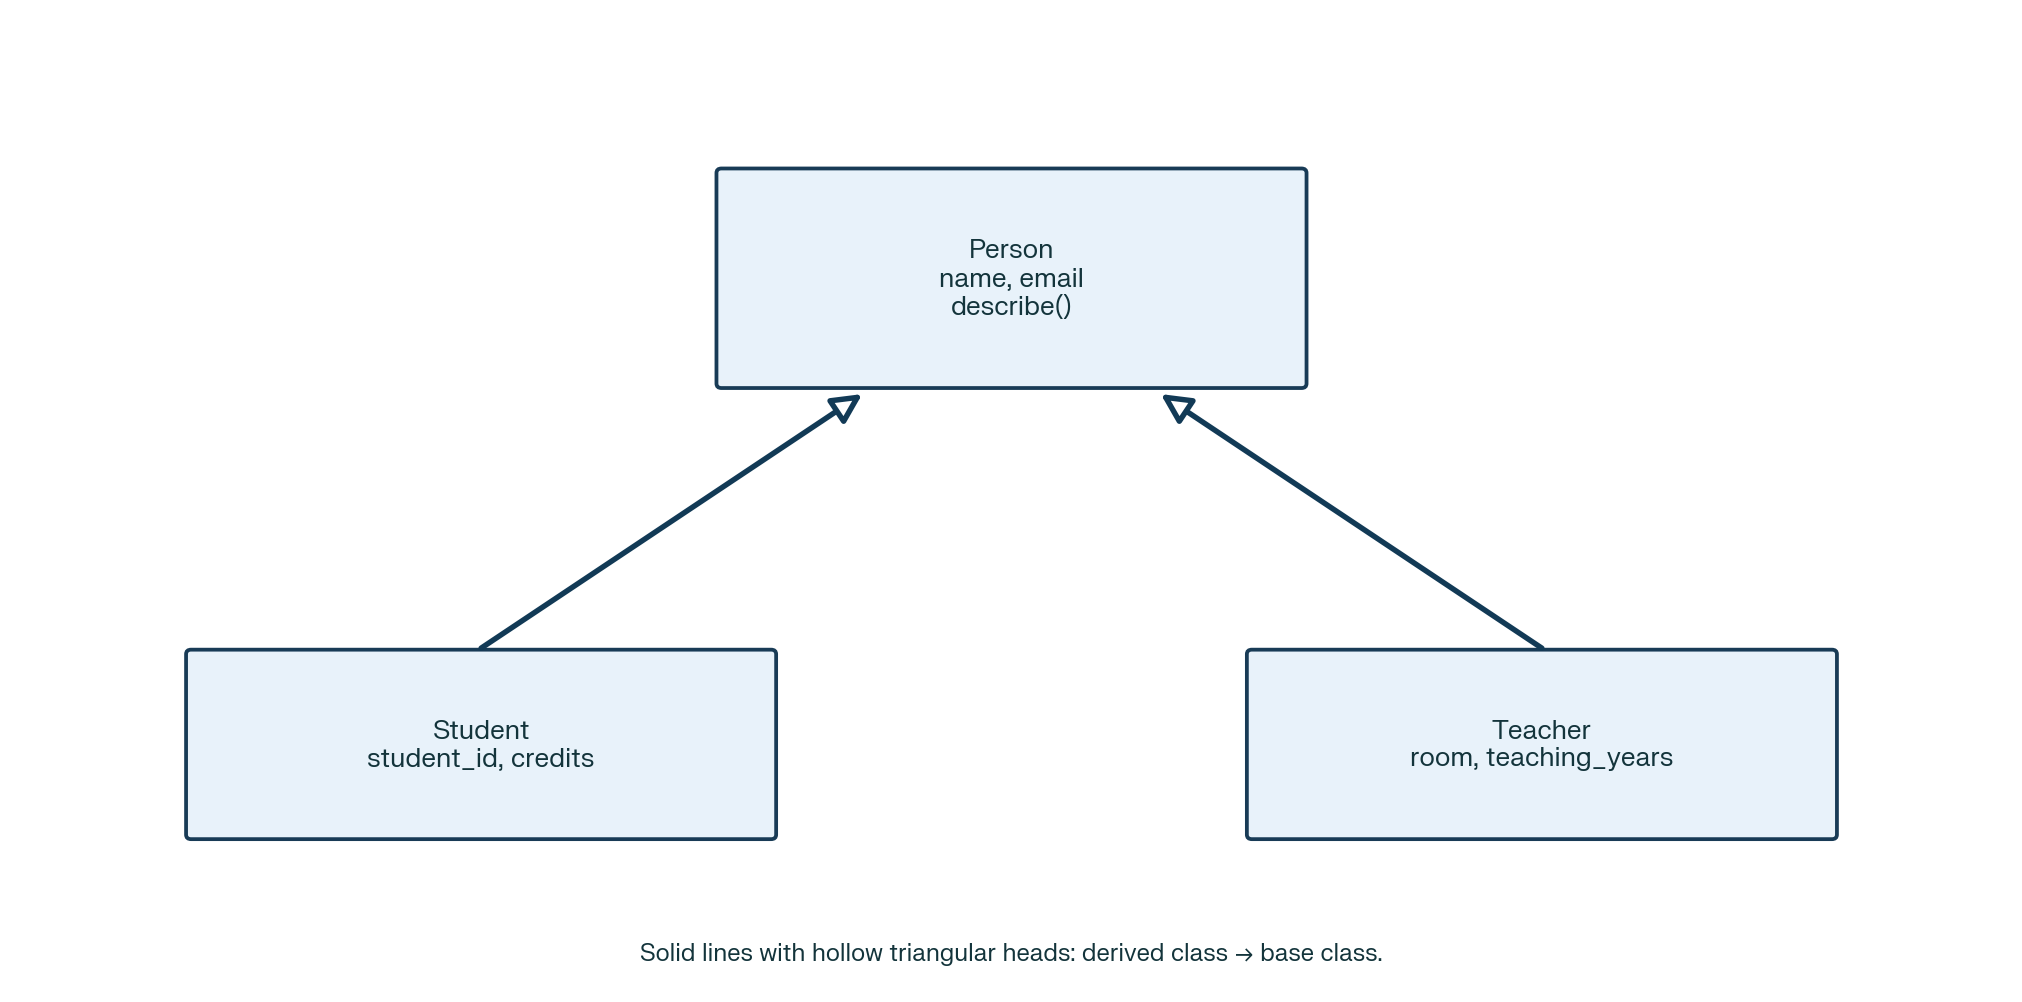
" width="1000">

## 2. Define a base class

The base class groups common state and operations. In this example:
- `__init__` establishes the name and email address.
- `update_email_domain()` changes the domain while preserving the part before `@`.
- `describe()` returns a simple description.

The email checks are minimal and serve only this example; they are not a complete email validation system.

In [ ]:
class Person:
    def __init__(self, name, email):
        self.name = name
        self.email = email

    def update_email_domain(self, new_domain):
        if not new_domain or "@" in new_domain:
            raise ValueError("Provide a nonempty domain without @.")
        local, separator, _ = self.email.partition("@")
        if not separator or not local:
            raise ValueError("The current email does not have the expected format.")
        self.email = f"{local}@{new_domain}"

    def describe(self):
        return f"{self.name} <{self.email}>"

## 3. Create derived classes

The syntax is `class DerivedClass(BaseClass):`.

Common data is initialized through `super().__init__(...)`. Each derived class then establishes its specific instance attributes.

`student_id` is an identifier, and `credits` is a number of credits. The names aim to make each value's meaning clear.

In [19]:
class Student(Person):
    def __init__(self, name, email, student_id, credits=0):
        super().__init__(name, email)
        self.student_id = student_id
        self.credits = credits

class Teacher(Person):
    def __init__(self, name, email, room, teaching_years=0):
        super().__init__(name, email)
        self.room = room
        self.teaching_years = teaching_years

bob = Student("Bob", "bob@escola.pt", "1234")
pat = Teacher("Pat", "pat@escola.pt", "A123", 2)

print(vars(bob))
print(vars(pat))

{'name': 'Bob', 'email': 'bob@escola.pt', 'student_id': '1234', 'credits': 0}
{'name': 'Pat', 'email': 'pat@escola.pt', 'room': 'A123', 'teaching_years': 2}


### Use an inherited method

Neither `Student` nor `Teacher` overrides `update_email_domain()` or `describe()`. Their instances can use these methods through inheritance.

There is no need to copy the method bodies into each derived class.

In [20]:
bob.update_email_domain("campus.pt")
pat.update_email_domain("campus.pt")

print(bob.describe())
print(pat.describe())

Bob <bob@campus.pt>
Pat <pat@campus.pt>


## 4. What does `super()` do?

`super()` calls a method from the next class in the inheritance order on the same object, without creating a new object.

In this single-inheritance example, `super().__init__(name, email)` finds the initializer in `Person`. That initializer works on the same `Student` or `Teacher` instance being prepared.

This is especially useful with multiple inheritance, where Python follows a defined order to find the next method.



As it is shown in the Figure, the base and derived initializers establish attributes on the same instance.

This diagram contains 3 explicit arrows.

<img src="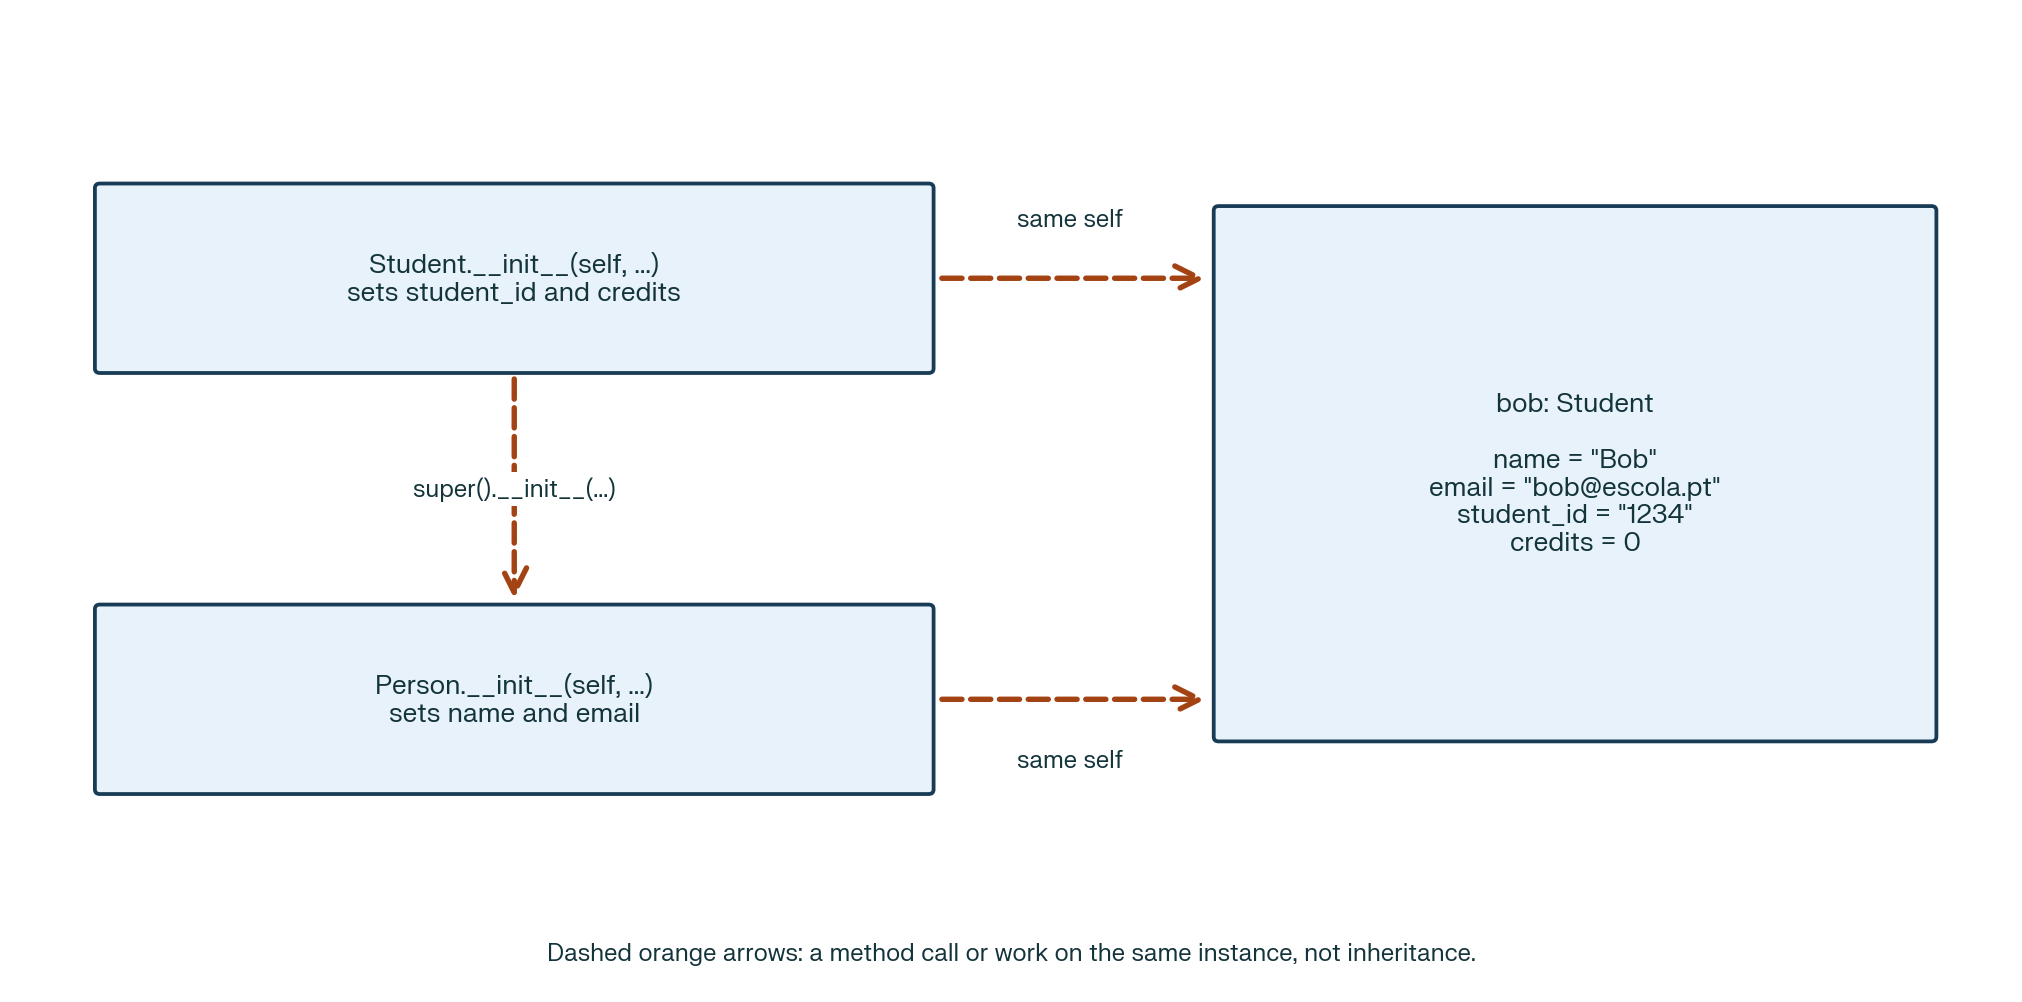
" width="1000">

### What if the derived class does not define `__init__`?

If a derived class does not define its own initializer, it can use the inherited initializer. There is no need to write an `__init__` that merely repeats the call to the base when there is nothing to add.

In [ ]:
class Visitor(Person):
    pass

visitor = Visitor("Ana", "ana@escola.pt")
print(visitor.describe())

Ana <ana@escola.pt>


### What if we define an initializer without calling the base?

The base initializer does not automatically run in addition to an initializer we override. If the common state is needed, we must establish it, normally by calling `super().__init__()`.

The following example deliberately omits that step. The instance is created, but it lacks `name` and `email`, which `describe()` needs.

In [ ]:
class StudentWithoutSuper(Person):
    def __init__(self, student_id):
        self.student_id = student_id

incomplete = StudentWithoutSuper("9999")
try:
    print(incomplete.describe())
except AttributeError:
    print("Expected attributes are missing: the Person state was not initialized.")

Expected attributes are missing: the Person state was not initialized.


## 5. Check relationships between classes

`isinstance(object, Class)` checks whether an object is an instance of that class or a derived class.

`issubclass(Derived, Base)` checks a relationship between classes.

`type(object)` identifies the concrete type. It does not replace `isinstance()` when we also want to accept instances of derived classes.

In [ ]:
print(isinstance(bob, Student))
print(isinstance(bob, Person))
print(isinstance(bob, Teacher))
print(issubclass(Student, Person))
print(type(bob) is Person)

True
True
False
True
False


## 6. Overriding methods

A derived class can define a method with the same name as a base-class method.

When that method is called on a derived instance, Python finds the appropriate implementation through attribute lookup.

An override can replace an operation or extend it by calling `super()`.

We will use a book container. The base class appends books at the end of its list; the bookshelf allows a position to be specified.

In [ ]:
class Book:
    def __init__(self, name, author):
        self.name = name
        self.author = author

    def describe(self):
        return f"{self.name} ({self.author})"

class BookContainer:
    def __init__(self):
        self.books = []

    def add_book(self, book):
        self.books.append(book)

    def list_books(self):
        return [book.describe() for book in self.books]

class Bookshelf(BookContainer):
    def add_book(self, book, position=None):
        if position is None:
            super().add_book(book)
        else:
            self.books.insert(position, book)



In the figure, Bookshelf overrides add_book while retaining other inherited methods, such as list_books.

This diagram contains 3 explicit arrows.

<img src="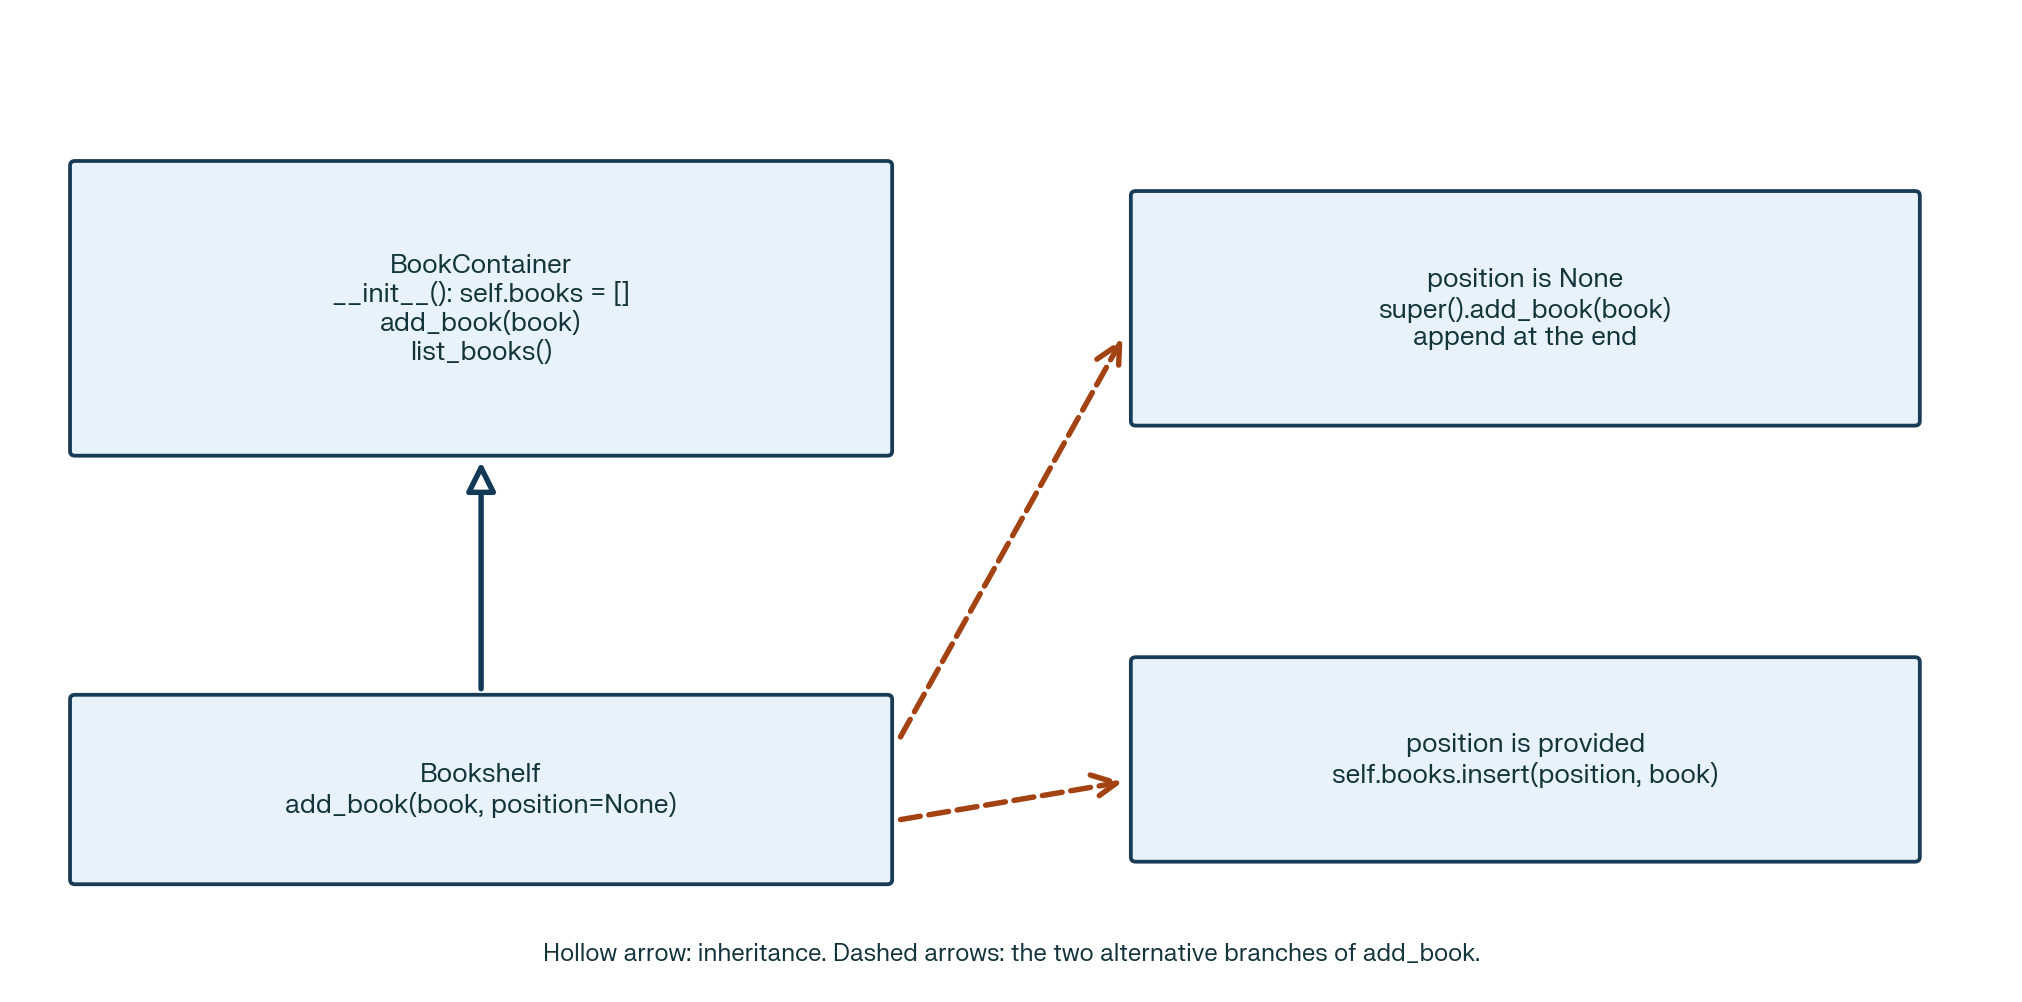
" width="1000">

### Preserve expected calls

`position` is optional: `shelf.add_book(book)` still works as it does in the base-class interface.

If position were required, a valid call for `BookContainer` would no longer work with `Bookshelf`. Reusing a method name does not, on its own, guarantee a compatible interface.

Here, `append()` adds at the end. `insert(0, book)` inserts at the beginning. Positions follow the usual Python list rules.

In [ ]:
book_a = Book("Book A", "Author A")
book_b = Book("Book B", "Author B")
book_c = Book("Book C", "Author C")

container = BookContainer()
container.add_book(book_a)
container.add_book(book_b)

shelf = Bookshelf()
shelf.add_book(book_a)
shelf.add_book(book_b, position=0)
shelf.add_book(book_c)

print("Container:", container.list_books())
print("Bookshelf:", shelf.list_books())

Container: ['Book A (Author A)', 'Book B (Author B)']
Bookshelf: ['Book B (Author B)', 'Book A (Author A)', 'Book C (Author C)']


### Base-class state is not a shared global list

`BookContainer.__init__` creates `self.books = []` for each new instance. The container and bookshelf therefore have independent lists.

However, they can hold references to the same `Book` objects. An independent list does not imply that every book has been copied.

In [ ]:
print(container.books is shelf.books)
print(container.books[0] is shelf.books[1])

False
True


## 7. Add state and extend behavior

In this teaching model, `Thesis` is a specialized book. It reuses the `Book` initializer, adds a grade, and extends `describe()`.

`super().describe()` obtains the common part of the description; the derived class adds specific information. The names and values below are only example data.

In [ ]:
class Thesis(Book):
    def __init__(self, name, author, grade):
        super().__init__(name, author)
        self.grade = grade

    def describe(self):
        return f"{super().describe()} — grade: {self.grade}"

thesis = Thesis("Study of Algorithms", "Ana Silva", 18)
print(thesis.describe())
print(isinstance(thesis, Book))

Study of Algorithms (Ana Silva) — grade: 18
True


## 8. Integrated example: a specialized bonus

A base card calculates a bonus of 5% of the total product cost. `PlatinumCard` adds 5% to the bonus calculated by the base.

Pay attention to the basis of the calculation:
- For a purchase total of 100, the base bonus is 5.
- Adding 5% of 5 adds 0.25.
- The final bonus is 5.25, not 10.


In [ ]:
class Product:
    def __init__(self, name, price):
        self.name = name
        self.price = price

class BonusCard:
    def __init__(self):
        self.products_bought = []

    def add_product(self, product):
        self.products_bought.append(product)

    def calculate_bonus(self):
        total = sum(product.price for product in self.products_bought)
        return total * 0.05

class PlatinumCard(BonusCard):
    def calculate_bonus(self):
        base_bonus = super().calculate_bonus()
        return base_bonus * 1.05

In [ ]:
card = BonusCard()
platinum = PlatinumCard()

for current_card in (card, platinum):
    current_card.add_product(Product("Book", 40))
    current_card.add_product(Product("Backpack", 60))

print(f"Base bonus: {card.calculate_bonus():.2f}")
print(f"Platinum bonus: {platinum.calculate_bonus():.2f}")

Base bonus: 5.00
Platinum bonus: 5.25


`PlatinumCard` does not need to repeat `__init__` or `add_product()` because the inherited implementations already meet its needs.

Multiplying by `1.05` increases the base result by 5%. It does not add five percentage points to the initial rate. If that were the intended rule, the calculation would need to be different.

## 9. Types of inheritance

These names describe the shape of a hierarchy. They are not additional language keywords.

| Type | Structure |
|---|---|
| Single | A class has one direct base |
| Multiple | A class has several direct bases |
| Multilevel | There is a chain of specializations |
| Hierarchical | Several classes derive from the same base |
| Hybrid | Combines earlier forms; a diamond is one example |

The same hierarchy can exhibit more than one of these characteristics.




Schematic inheritance examples. In every figure, arrows point toward the base class.

<img src="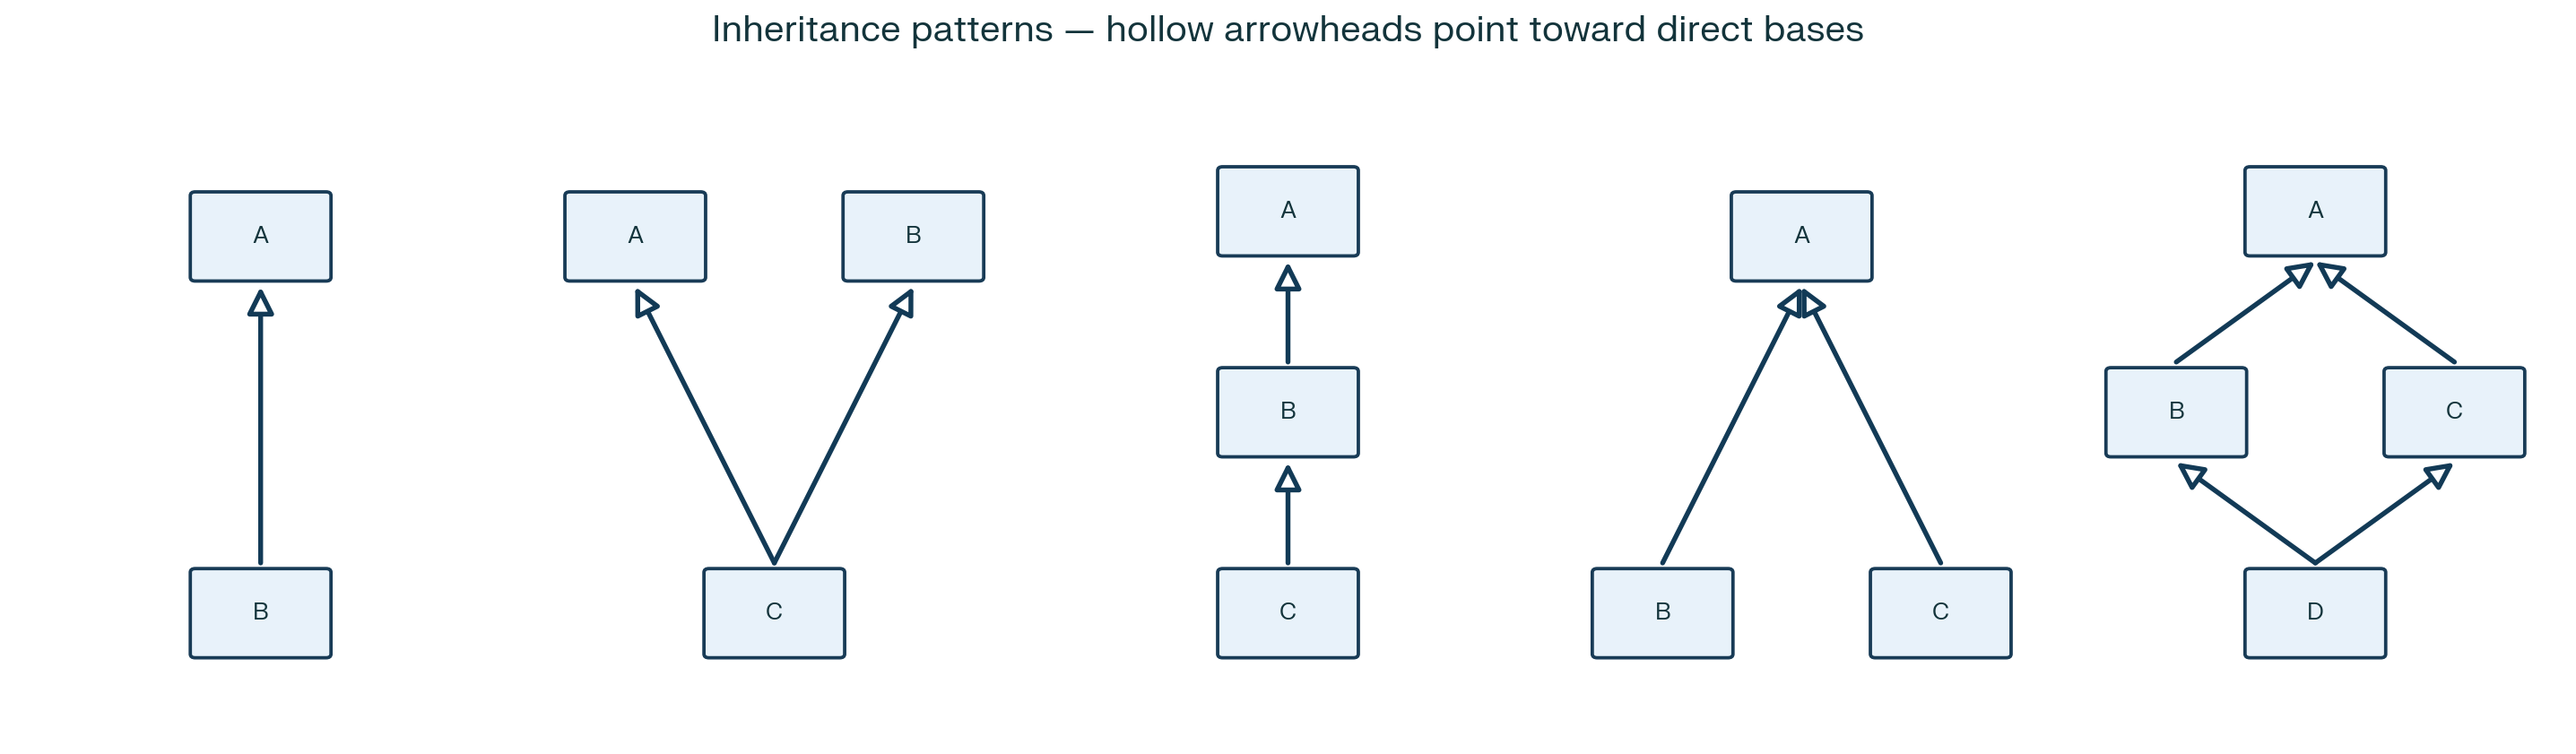
" width="1000">

### Single, multilevel, and hierarchical inheritance in one example

`Car` inherits from `Vehicle`. `SportsCar` inherits from `Car`, forming a chain. `Truck` also inherits from `Vehicle`, creating a branch.

Each class is defined only once so that behavior does not depend on replacing an earlier definition in the notebook.

In [ ]:
class Vehicle:
    def vehicle_info(self):
        return "I am a vehicle."

class Car(Vehicle):
    def car_info(self):
        return "I am a car."

class SportsCar(Car):
    def sportscar_info(self):
        return "I am a sports car."

class Truck(Vehicle):
    def truck_info(self):
        return "I am a truck."

In [ ]:
sports_car = SportsCar()
truck = Truck()

print(sports_car.vehicle_info())
print(sports_car.car_info())
print(sports_car.sportscar_info())
print(truck.vehicle_info())
print(truck.truck_info())
print(issubclass(SportsCar, Vehicle))

I am a vehicle.
I am a car.
I am a sports car.
I am a vehicle.
I am a truck.
True


## 10. Multiple inheritance: combine capabilities

A class can specify several bases inside its parentheses. Here, a device combines printing and scanning capabilities.

The methods have different names, so there is no conflict between two implementations with the same name in this example.

**Note:** Avoid adding bases only because you want to use some function they contain. The combination should also make sense in the model.

In [ ]:
class Printable:
    def print_document(self):
        return "Document printed."

class Scannable:
    def scan_document(self):
        return "Document scanned."

class MultifunctionDevice(Printable, Scannable):
    pass

device = MultifunctionDevice()
print(device.print_document())
print(device.scan_document())

Document printed.
Document scanned.


## 11. Optional exploration: diamonds and MRO

If several bases provide the same method, Python needs an order in which to look for it. The MRO, or method resolution order, can be inspected through `Class.__mro__`.

In the following diamond, `D` derives from `B` and `C`, which derive from `A`. The order for `D` is:

```text
D → B → C → A → object
```

`super()` continues lookup in that order, starting after the class in which the method was defined. Therefore, inside `B.process()` called in this context, the next method is in `C`, even though `B` has `A` as its direct base.

There is no need to study the linearization algorithm in this lesson. The important point is not to interpret `super()` as “create a parent object” or “always call the direct parent.”

In [ ]:
class A:
    def process(self):
        return ["A"]

class B(A):
    def process(self):
        return ["B"] + super().process()

class C(A):
    def process(self):
        return ["C"] + super().process()

class D(B, C):
    pass

print([class_type.__name__ for class_type in D.__mro__])
print(D().process())

['D', 'B', 'C', 'A', 'object']
['B', 'C', 'A']


In this example we have a diamond; Therefore when D().process() is called,
- B.process() process is called
- Inside B, super().process() calls C.process(), because C comes after B in D’s MRO.
- Inside C, super().process() calls A.process()

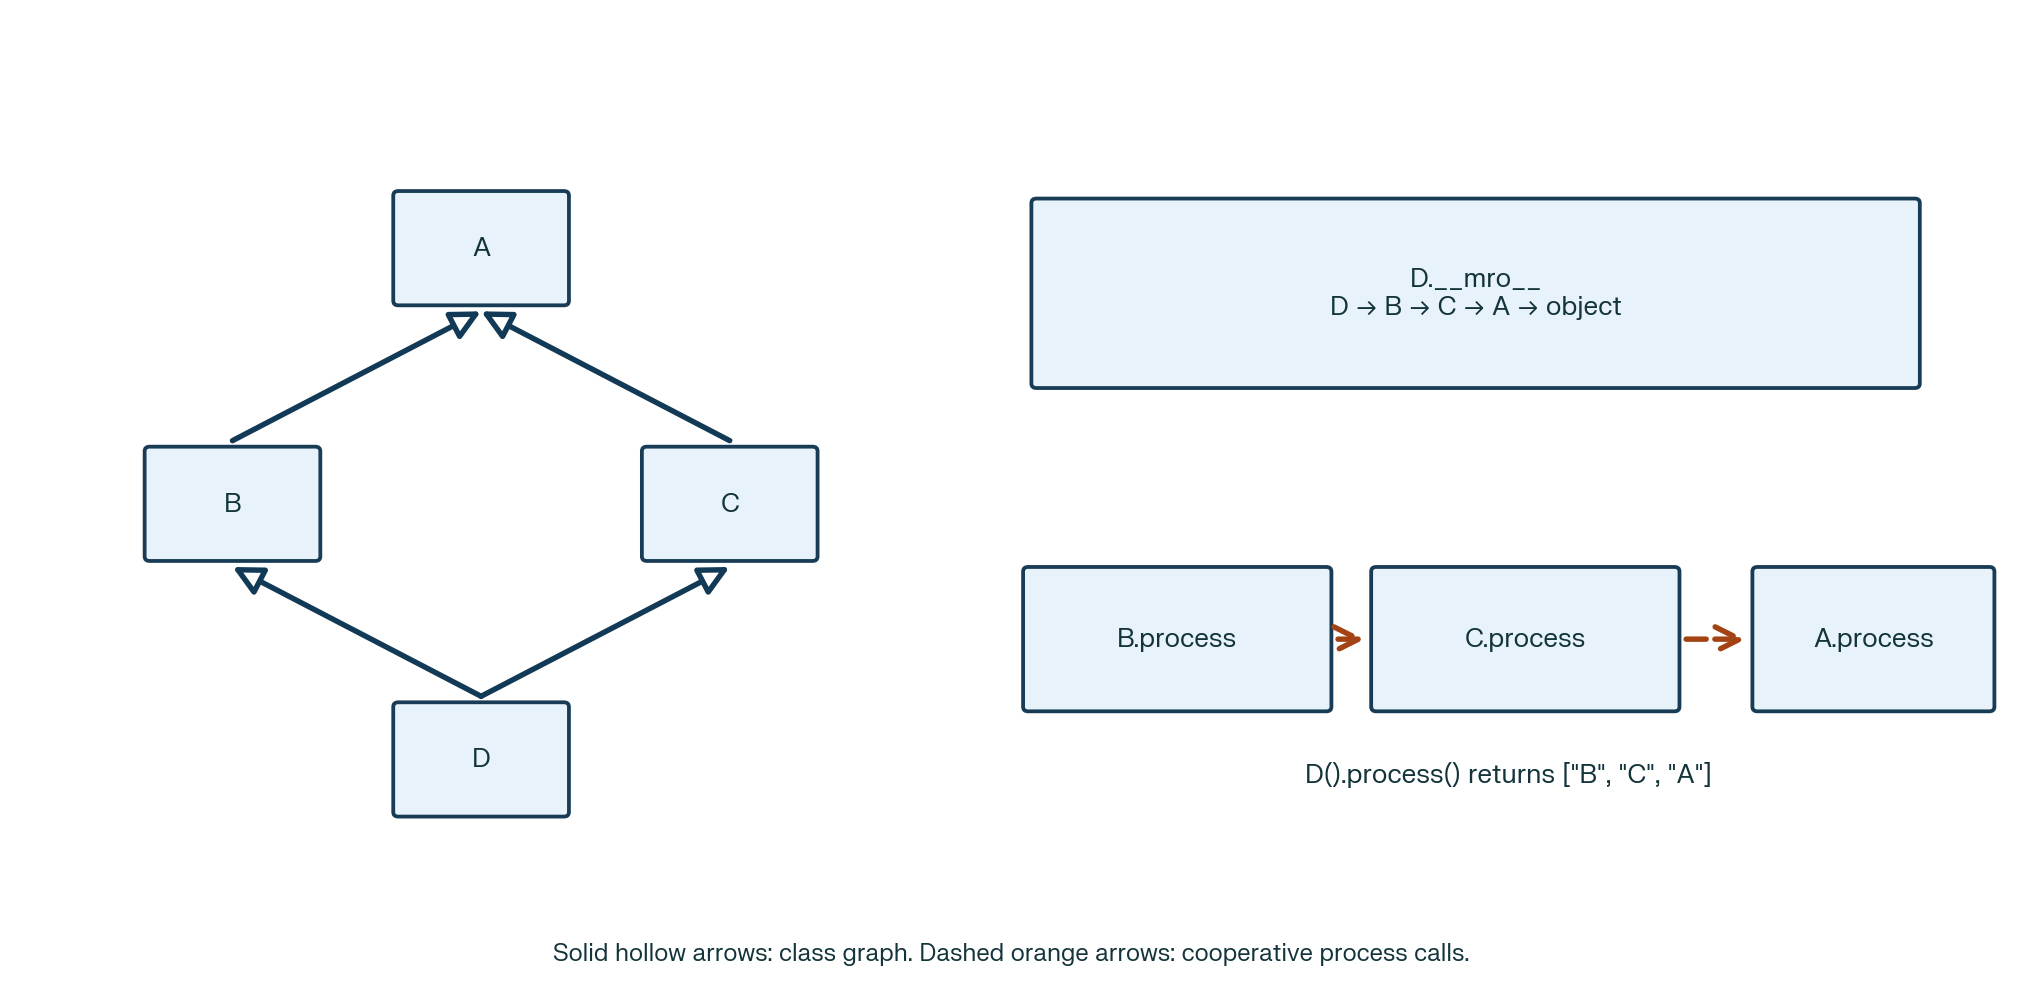


Python does not automatically execute every implementation merely because multiple inheritance exists. If a method stops this cooperation, later methods are not called along that path.

The participating methods also need compatible arguments. In real projects, this requirement makes multiple inheritance a choice that needs care.

## 12. Inheritance or composition?

Inheritance expresses an “is-a” relationship. Composition associates objects through attributes: one object “has” or “uses” another.

An employee is a person, but is not a company. The company can be stored in an employee attribute.

For that reason, `Employee(Person, Company)` would be misleading in this model, even if it allowed methods from both classes to be reused.


Employee inherits from Person and holds a reference to Company. These relationships have different meanings.

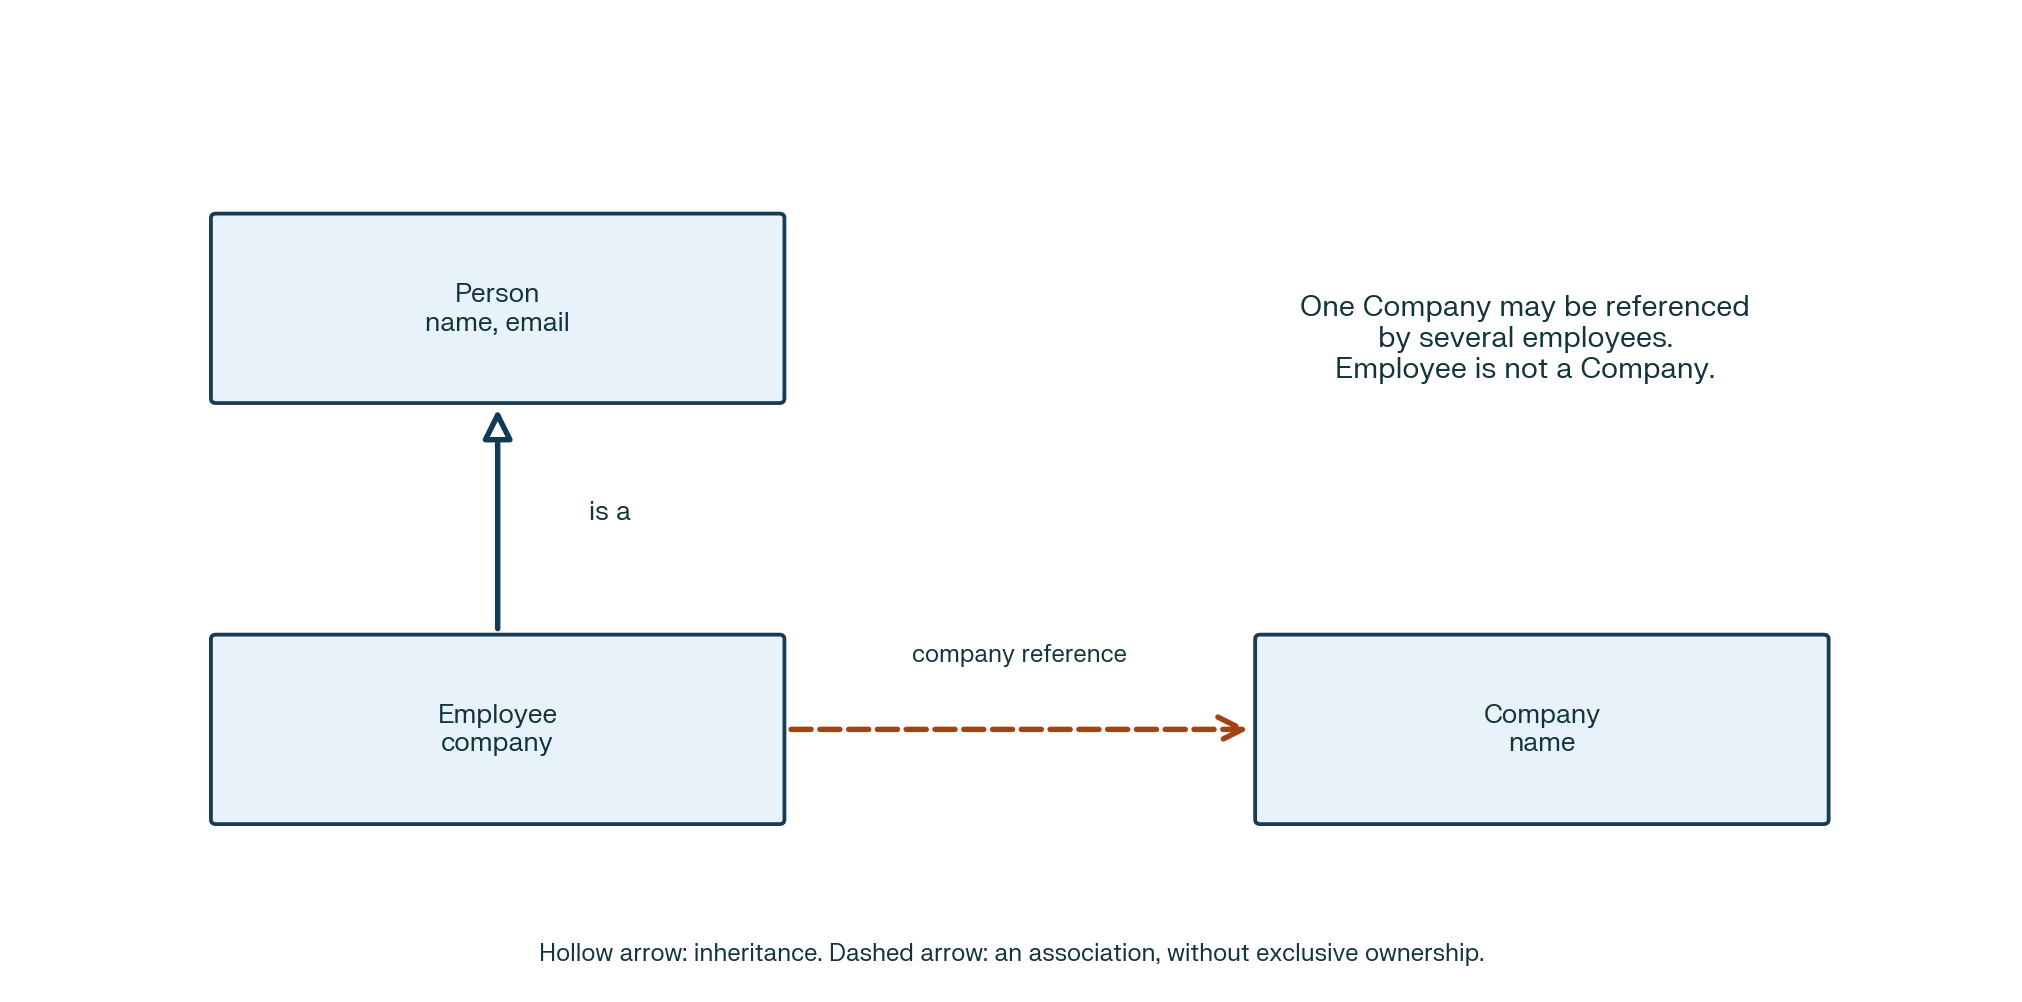

In [ ]:
class Company:
    def __init__(self, name):
        self.name = name

class Employee(Person):
    def __init__(self, name, email, company):
        super().__init__(name, email)
        self.company = company

company = Company("Example Company")
employee = Employee("Rita", "rita@empresa.pt", company)

print(employee.describe())
print(employee.company.name)
print(isinstance(employee, Person))
print(isinstance(employee, Company))
print(employee.company is company)

Rita <rita@empresa.pt>
Example Company
True
False
True


## 14. Practice

Try each exercise first, and open the suggested solution only afterward.

### Exercise 1 — Digital book
Create `DigitalBook(Book)` with an additional `file_format` attribute.
- Initialize the name and author using `super()`.
- Override `describe()` by adding the format to the base result.
- Check that the object is still an instance of `Book`.

In [ ]:
# Write the DigitalBook class and create a book in PDF format.

### Exercise 2 — Another card

Create `GoldCard(BonusCard)` that adds 10% to the base bonus using `super()`.

Do not repeat the initializer or the method for adding products. Under this fictional rule, purchases totaling 100 should produce a bonus of 5.50.